# fmow: image representations and source acquisitions

The question is whether a static epistemic summary characterizes which additional information is useful. This notebook uses genuine images, recorded domains and recorded target labels. It never manufactures domains from target classes. It reports negative outcomes without changing matching criteria.

This is a reproducible pilot with a **custom group-disjoint split**, not a completed CVPR benchmark. All outputs, observations, model states, figures, sources and an executed notebook are saved beneath `workbook/fmow_acquisition_<UTC>/`. Run the notebook using the `reach-aistats` environment or `scripts/run_wilds_notebook.py`.


## Sources and what each contributes

- Koh et al., [WILDS (ICML 2021)](https://arxiv.org/abs/2012.07421), [dataset descriptions](https://wilds.stanford.edu/datasets/): source/domain meaning and benchmark provenance. Our group split is custom; our numbers are not official WILDS benchmark scores.
- Bandi et al., [CAMELYON17](https://doi.org/10.1109/TMI.2018.2867350): tumor and hospital annotations. [WILDS loader](https://github.com/p-lambda/wilds/blob/main/wilds/datasets/camelyon17_dataset.py) documents patient/slide fields and hospital numbering.
- Christie et al., [Functional Map of the World (CVPR 2018)](https://openaccess.thecvf.com/content_cvpr_2018/html/Christie_Functional_Map_of_CVPR_2018_paper.html), [WILDS loader](https://github.com/p-lambda/wilds/blob/main/wilds/datasets/fmow_dataset.py): land-use classes, region and temporal metadata.
- [Camelyon public mirror](https://huggingface.co/datasets/wltjr1007/Camelyon17-WILDS), revision `d784d5344ba6c967f83f9f3d9b2f1e2a4d6eb78f`; [FMoW mirror](https://huggingface.co/datasets/danielz01/fMoW), revision `8a27a7988a20341352b85bf0e65e88a6c1337f1c`: transport alternatives. These are third-party mirrors, not independently verified official copies. The adapter also accepts official local WILDS folders. The original server failed certificate verification; FMoW mirror requires user access.
- Hüllermeier & Waegeman, [uncertainty concepts](https://doi.org/10.1007/s10994-021-05946-3): distinguish uncertainty about predictions from stochastic outcomes. We do not estimate aleatoric uncertainty here.
- Gal & Ghahramani, [MC dropout (ICML 2016)](https://proceedings.mlr.press/v48/gal16.html): sampled predictive distributions. Finite sample extrema are not confidence bounds on the true probability.
- [DAPPr paper](https://arxiv.org/abs/2605.00600) and [loss implementation](https://github.com/MaxwellYaoNi/DAPPr/blob/main/DAPPr.py): baseline loss and scalar K/sum(alpha). We adapt the head/encoder and schedule, not reproduce the original architecture/training.
- [Probly](https://github.com/pwhofman/probly): actual sampler, representation and quantification interfaces. Installed version is saved. Our existing adapter exposes probability endpoints and labels their semantics.
- Hoeffding, [Probability Inequalities (1963)](https://doi.org/10.1080/01621459.1963.10500830): frequency boxes for bounded independent empirical-population draws; union bound allocates error over boxes. This is not an iid-patch guarantee across new patients.
- Charnes & Cooper, [linear fractional programming (1962)](https://doi.org/10.1002/nav.3800090303): sharp ratio extrema over the declared linear joint-mass set.
- Local `acquisition_counterexample.ipynb`, `real/beta_acquisition.py`, `real/source_acquisition.py`: exact toy proof, Beta conjugacy, total-variance action values and joint-mass implementation. Beta conjugacy follows directly by multiplying a Bernoulli likelihood by a Beta density. All new code is archived in each run.

- He et al., [Deep Residual Learning (CVPR 2016)](https://openaccess.thecvf.com/content_cvpr_2016/html/He_Deep_Residual_Learning_CVPR_2016_paper.html), [torchvision ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html): frozen encoder and preprocessing. [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html): finite-cell quantization.


## 1. Freeze the protocol before looking at results

Camelyon uses known hospitals **0 and 3**, candidate hospital **2**, and tumor=1. FMoW uses known regions **Americas and Europe**, candidate **Asia**, and retains full class labels for classification. For the binary prevalence/label-bound target, FMoW uses the modal training class with a deterministic label tie-break, frozen before evaluating held-out labels.

Split groups by a seeded hash of identities only: approximately 60% fit, 20% reference, 20% evaluation per source. A Camelyon patient is a group; an FMoW location rounded to 0.01 degrees is a conservative spatial group. All repeated images within a group stay together. Small numbers of held-out patients are explicitly counted; image counts do not imply equally many independent patients.

For FMoW, this pilot uses observations before 2016; later years are retained in the record audit but excluded from the current experiments. Thus the completed experiment concerns region shift, not a validated temporal-shift result. We preserve original split fields for audit, but deliberately do not claim the official WILDS split: a source-identity acquisition comparison requires both known sources in the evaluation mixture.


In [1]:
# Goal: save a fixed configuration and create a fresh output directory.
from pathlib import Path
import os,sys,json,shutil,hashlib,importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=Path.cwd()
if not (ROOT/'real/wilds_records.py').exists():
    ROOT=ROOT/'Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS'
sys.path.insert(0,str(ROOT))
DATASET='fmow'
KIND='acquisition'
DATA_ROOT=Path(os.environ.get('WILDS_DATA_ROOT',str(ROOT/'data/wilds/fmow-mirror')))
WEIGHTS=Path(os.environ.get('WILDS_ENCODER_WEIGHTS',str(ROOT/'data/wilds/resnet18-f37072fd.pth')))
SEED=20261030
RUN_DIR=ROOT/'workbook'/('fmow_acquisition_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ'))
RUN_DIR.mkdir(parents=True,exist_ok=False)
protocol=dict(dataset=DATASET,kind=KIND,seed=SEED,data_root=str(DATA_ROOT),image_cap_per_role_source=2000,
    epochs=30,mc_passes=30,cells=4,acquisition_repeats=5,group_split='60/20/20 fit/reference/evaluation',
    fmow_years='before 2016; later years excluded',mi_match_relative_tolerance=.01,action_margin=2)
(RUN_DIR/'protocol.json').write_text(json.dumps(protocol,indent=2))
source_nb=json.loads((ROOT/'fmow_acquisition.ipynb').read_text())
(RUN_DIR/'SOURCES.md').write_text(''.join(source_nb['cells'][1]['source']))
print('Outputs:',RUN_DIR)


Outputs: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/fmow_acquisition_20261030T094932286096Z


## 2. Read recorded fields and enforce leakage checks

The adapter supports official WILDS files and complete parquet splits from the listed mirrors. Missing fields, incomplete shards, missing source groups and non-unique record IDs are errors. Every selected row keeps its file/row or original image path. Labels do not determine the patient/location partition.

The empirical population is the retained dataset, not a national population, a hospital's clinical prevalence, or all global satellite imagery. Later resampling with replacement estimates behavior conditional on these records; it does not generate new independent patients or locations.


In [2]:
# Goal: audit source/group counts and persist the full partition before fitting or searching.
from real.wilds_records import read_records,group_partition,image_sample,save_data_audit
records=group_partition(read_records(DATASET,DATA_ROOT),SEED)
save_data_audit(records,DATA_ROOT,RUN_DIR,DATASET)
display(records.groupby(['source_name','role']).agg(records=('record_id','size'),groups=('group','nunique')))
assert records.groupby('group').role.nunique().max()==1


records  groups
source_name role                       
Americas    evaluation     8474    2701
            fit           24919    8106
            reference      8372    2701
Asia        evaluation     6451    2248
            fit           19203    6748
            reference      6547    2248
Europe      evaluation    11395    4244
            fit           35459   12732
            reference     11970    4244

## 3. Learn only from fit images; freeze the visual map

Uniformly sample at most 2,000 images per source and role, without class balancing. This caps compute and defines the pilot population; it does not preserve original domain prevalence. Full group assignments remain in the audit.

Extract ImageNet-pretrained ResNet18 features with a frozen encoder. Features and transformations are shared by CE and DAPPr heads. Training uses known-source fit images only, fixed 30 epochs and matched initialization/minibatch seeds. Reference/evaluation labels never select epochs. Candidate-source labels are excluded from neural training. This is a frozen-encoder adaptation, not end-to-end WILDS performance.


In [3]:
# Goal: persist image selection and extract reproducible visual features on the available GPU.
import torch
torch.set_num_threads(4)
DEVICE='cuda:0' if torch.cuda.is_available() else 'cpu'
from real.wilds_vision import extract_features,fit_predict,acquisition_bounds
sample=image_sample(records[~records.temporal_ood],protocol['image_cap_per_role_source'],SEED)
sample.to_csv(RUN_DIR/'selected_images.csv',index=False)
features=extract_features(sample,WEIGHTS,RUN_DIR,device=DEVICE)
print('Feature matrix:',features.shape,'device:',DEVICE)


Feature matrix: (18000, 512) device: cuda:0


## 4. Compare predictive representations on source ID/OOD images

ID means either known source; OOD means the declared candidate source. Classes can overlap completely. This is domain novelty, not held-out-class novelty.

The CE head uses actual Probly MC-dropout sampling (30 passes). The wrapper returns lower/upper class probabilities over the finite sampled predictors. Maximum coordinate width summarizes the envelope; MI summarizes predictive disagreement. Finite MC bounds have no population coverage guarantee. DAPPr uses its published loss and original scalar K/sum(alpha). Negative maximum softmax is an additional diagnostic.

All scores use the same evaluation images. Save predictions, envelopes, heads, training history, classification accuracy and tie-correct OOD AUROC/AUPR. Probly's raw AUROC is saved separately because its installed version mishandles ties. These detection results alone cannot establish acquisition insufficiency.


In [4]:
# Goal: train matched heads and preserve actual Probly representations and detection metrics.
scores=fit_predict(sample,features,RUN_DIR,seed=SEED,epochs=protocol['epochs'],device=DEVICE,mc_passes=protocol['mc_passes'])
display(pd.read_csv(RUN_DIR/'accuracy.csv'))
display(pd.read_csv(RUN_DIR/'ood_scores.csv'))


/home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/real/wilds_vision.py:63: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  mean=x[fit.to_numpy()].mean(0);std=x[fit.to_numpy()].std(0).clamp_min(.01)


,method,source,n,accuracy
0,ce,0,2000,0.2425
1,ce,1,2000,0.2405
2,ce,2,2000,0.1200
3,dappr,0,2000,0.2690
4,dappr,1,2000,0.2600
5,dappr,2,2000,0.1310


,method,auroc,probly_raw_auroc,probly_auroc_difference,aupr_ood,dappr_aupr_id,fpr95
0,mc_mi,0.573703,0.573704,6.250000e-08,0.402949,0.726283,0.89975
1,mc_width,0.545837,0.545837,1.250000e-07,0.364235,0.710722,0.91200
2,dappr_eu,0.560500,0.560500,6.250000e-08,0.378526,0.711908,0.91950
3,negative_max_softmax,0.525669,0.525669,0.000000e+00,0.343479,0.705688,0.89250


## 5. Construct source-compatible probability bounds and acquire information

Fit four KMeans cells using only known-source fit features. Let $z_{sc}=P(S=s,C=c)$, with nonnegative entries summing to one. Reference estimates constrain $P(C\mid S)$, deployment images constrain $P(C)$, and revealed source IDs constrain $P(S)$. Row-conditional boxes become linear inequalities $l_{sc}\sum_d z_{sd}\le z_{sc}\le u_{sc}\sum_d z_{sd}$. Ratio optimization yields sharp lower/upper values *within this declared set*.

Keep three different targets explicit:

1. Known membership: $P(S=0\mid C,S\in\{0,1\})$.
2. Candidate membership: $P(S=2\mid C)$, relative to this specified candidate source.
3. Reference target probability: $P(Y=event\mid C)$ under fixed equal known-source weights. Estimate target rates **within source and cell**; do not assume labels independent of images given source.

Initial observations are 128 reference inputs per source, 128 deployment inputs, 32 deployment IDs and 16 target labels per known-source/cell stratum. Four sweeps add deployment inputs, IDs, reference inputs, or stratified labels. Budgets are additional fields: n for inputs/IDs, 3*floor(n/3) for reference inputs and 2*C*floor(n/(2*C)) for labels. A reference service supplies stratum selection. Label acquisitions reveal only Y in that selected stratum; other channels hide unrequested fields.

All draws resample real records. Hoeffding boxes use a union allocation across the run. The guarantee is conditional on fixed empirical source populations and the mixture model. **Reference-to-evaluation source-law stability is an assumption**, checked descriptively in `source_cell_law_audit.csv`; group separation does not guarantee it. Empty feasible sets are reported, never turned into certainty. Possible zero conditioning mass returns [0,1] and an explicit status.

The source wrapper uses the same Probly lower/upper interface, but its events are source memberships, not neural class probabilities. It is not valid to present its width as an estimate of neural MI or as an equal-information superiority comparison. The label and membership widths are separate targets, not an additive epistemic decomposition. No arbitrary unknown-source detection or exact input-only identification floor is claimed from these finite reference estimates.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Failed to find font weight 300 for STIXGeneral, now using 400.


... (662 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


,action,budget,target,mean_width,empty_fraction,undefined_fraction
0,inputs,0,candidate_membership,0.986577,0.0,0.05
1,inputs,0,known_membership,0.999092,0.0,0.40
2,inputs,0,reference_label,0.777869,0.0,0.05
3,inputs,32,candidate_membership,0.986573,0.0,0.05
4,inputs,32,known_membership,0.999092,0.0,0.40
5,inputs,32,reference_label,0.777869,0.0,0.05
6,inputs,128,candidate_membership,0.986573,0.0,0.00
7,inputs,128,known_membership,0.999092,0.0,0.40
8,inputs,128,reference_label,0.777869,0.0,0.05
9,inputs,512,candidate_membership,0.986432,0.0,0.00


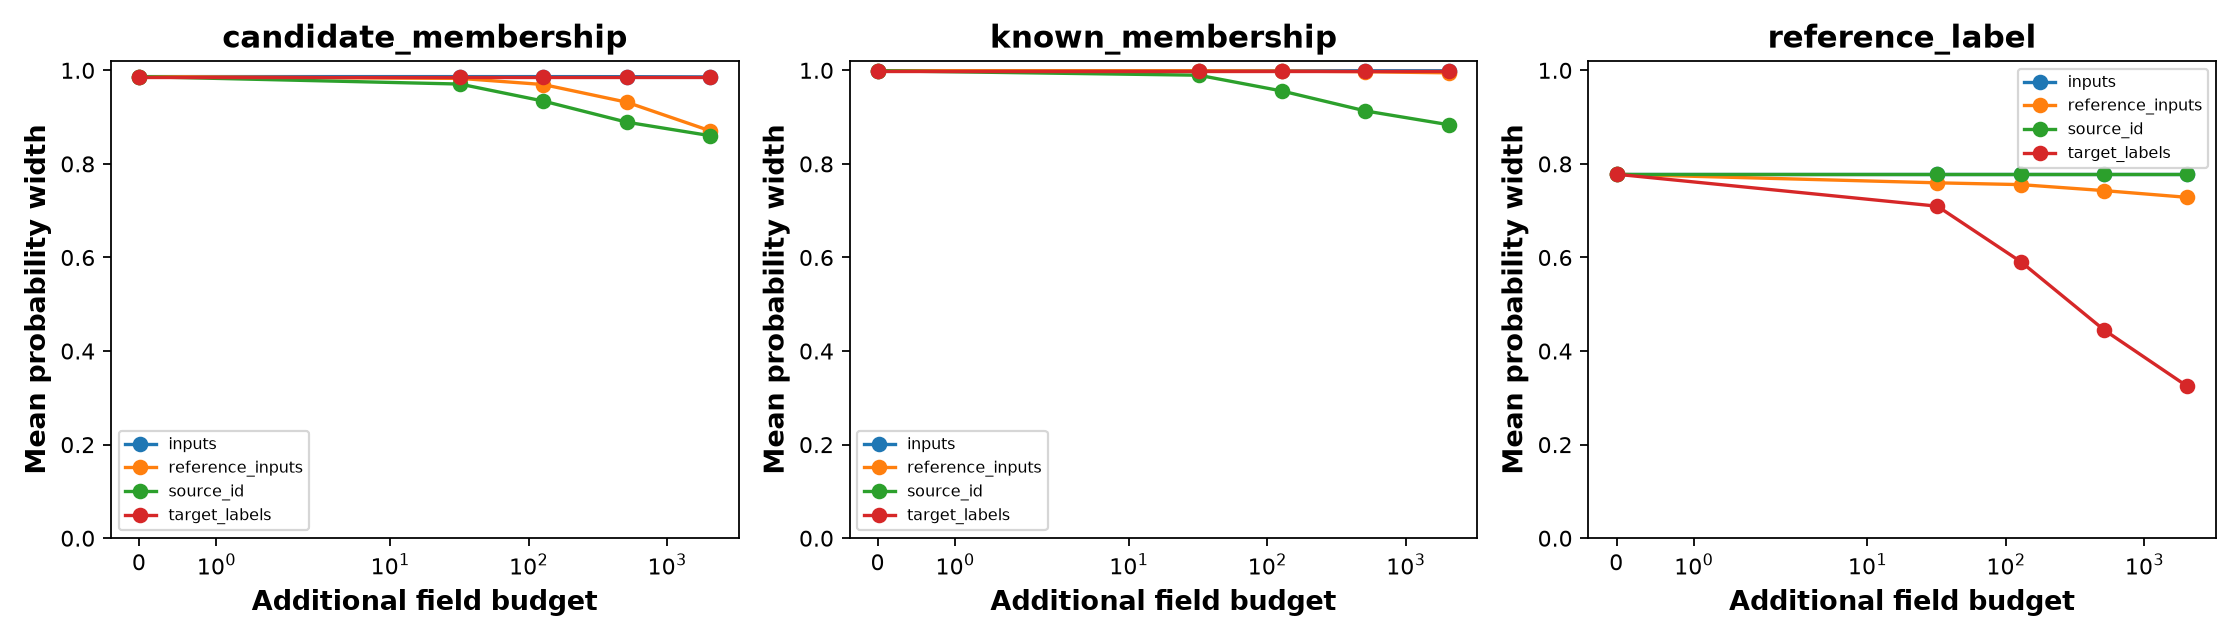

# Image acquisition pilot

{
  "status": "completed_pilot",
  "images": 18000,
  "empty_fraction": 0.0,
  "undefined_fraction": 0.11666666666666667,
  "mean_width": 0.8893240495460834
}

See acquisition_summary.csv, source_cell_law_audit.csv and ood_scores.csv. Different target widths are not an additive decomposition. This pilot does not establish superiority or a neural acquisition counterexample. The separate counterexample notebook checks its prespecified held-out endpoint. Patient/location counts, source-law transfer and the frozen encoder limit generalization; these are not official WILDS scores.

In [5]:
# Goal: update the declared information constraints and expose every interval and failure status.
summary=acquisition_bounds(sample,features,RUN_DIR,seed=SEED,n_cells=protocol['cells'],repeats=protocol['acquisition_repeats'])
display(summary)
display(Image(filename=str(RUN_DIR/'acquisition_bounds.png')))
intervals=pd.read_csv(RUN_DIR/'acquisition_intervals.csv')
result=dict(status='completed_pilot',images=len(sample),empty_fraction=float((intervals.status=='empty').mean()),
    undefined_fraction=float((intervals.status=='undefined_denominator_policy').mean()),mean_width=float(intervals.width.mean()))
(RUN_DIR/'result.json').write_text(json.dumps(result,indent=2))
report='# Image acquisition pilot\n\n'+json.dumps(result,indent=2)+'\n\n'+(
    'See acquisition_summary.csv, source_cell_law_audit.csv and ood_scores.csv. '
    'Different target widths are not an additive decomposition. This pilot does not establish superiority or a neural acquisition counterexample. '
    'The separate counterexample notebook checks its prespecified held-out endpoint. '
    'Patient/location counts, source-law transfer and the frozen encoder limit generalization; these are not official WILDS scores.')
(RUN_DIR/'RESULTS.md').write_text(report)
display(Markdown(report))


## 6. Preserve the experiment and its limitations

Save source code snapshots and package versions. The runner adds the executed notebook, execution status and SHA-256 artifact manifest even if execution fails. Negative counterexample outcomes remain negative; wide or empty intervals remain visible. No run is described as a successful paper-level result solely because code executed.


In [6]:
# Goal: archive the exact local implementations used for this run.
for path in list((ROOT/'real').glob('wilds_*.py'))+[ROOT/'real/beta_acquisition.py',ROOT/'real/source_acquisition.py',ROOT/'real/probability_bounds.py',ROOT/'scripts/build_wilds_notebooks.py']:
    shutil.copy2(path,RUN_DIR/path.name)
shutil.copy2(ROOT/'fmow_acquisition.ipynb',RUN_DIR/'source_notebook.ipynb')
(RUN_DIR/'versions.json').write_text(json.dumps({p:importlib.metadata.version(p) for p in ['numpy','scipy','pandas','torch','torchvision','probly','pyarrow','scikit-learn']},indent=2))
print('Saved results:',RUN_DIR)


Saved results: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/fmow_acquisition_20261030T094932286096Z
